# Statistical Business Analysis
This notebook calculates descriptive statistics, correlation, hypothesis tests, and regressions on sales data.

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## 1. Descriptive Statistics & Data Setup

In [ ]:
df = pd.read_csv('sales_data (4).csv')

# Generate simulated Marketing Spend to fulfill requirement
np.random.seed(42)
df['Marketing_Spend'] = (df['Total_Sales'] * 0.1) + np.random.normal(0, 5000, size=len(df))
df['Marketing_Spend'] = df['Marketing_Spend'].abs()

display(df[['Quantity', 'Price', 'Marketing_Spend', 'Total_Sales']].describe())

,Quantity,Price,Marketing_Spend,Total_Sales
count,100.000000,100.000000,100.000000,100.000000
mean,4.780000,25808.510000,12330.755701,123650.480000
std,2.588163,13917.630242,10155.570220,100161.085275
min,1.000000,1308.000000,135.620378,6540.000000
25%,2.750000,14965.250000,4818.804925,39517.500000
50%,5.000000,24192.000000,9299.230961,97955.500000
75%,7.000000,38682.250000,17933.926175,175792.500000
max,9.000000,49930.000000,44283.064078,373932.000000


## 2. Confidence Intervals & Data Distribution

Average Sales: $123650.48 ± $19874.13 (95% CI)


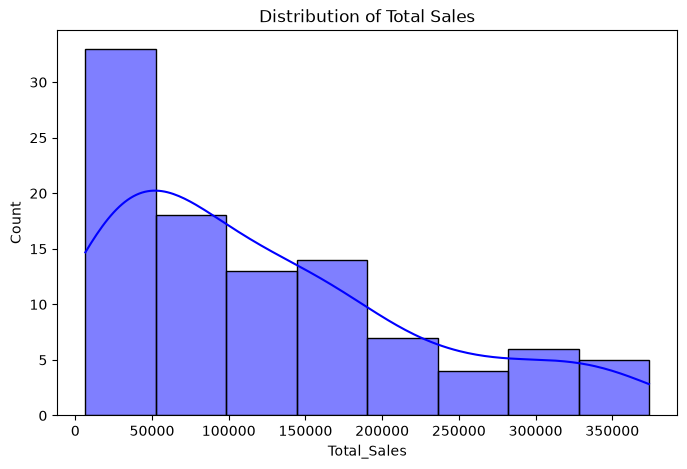

In [ ]:
# Calculate 95% Confidence Interval for Total Sales
mean_sales = df['Total_Sales'].mean()
std_sales = df['Total_Sales'].std(ddof=1)
n = len(df)
margin_error = stats.t.ppf(0.975, n-1) * (std_sales / np.sqrt(n))
print(f"Average Sales: ${mean_sales:.2f} ± ${margin_error:.2f} (95% CI)")

# Plot Histogram & Density
plt.figure(figsize=(8,5))
sns.histplot(df['Total_Sales'], kde=True, color='blue')
plt.title('Distribution of Total Sales')
plt.show()

## 3. Correlation Analysis

Pearson Correlation (Sales-Marketing): 0.91 (p-value: 3.2601e-39)


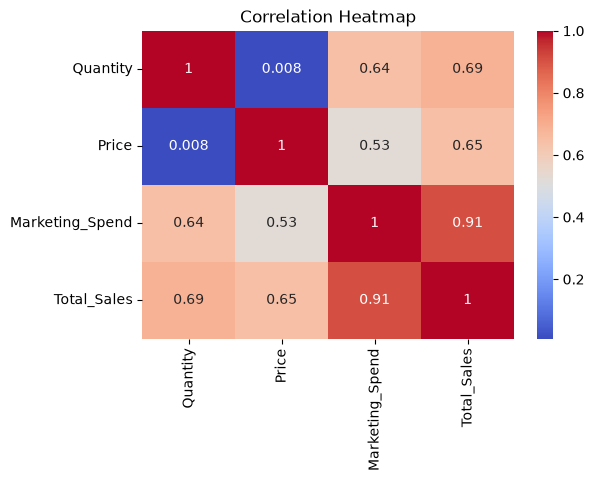

In [ ]:
corr, p_corr = stats.pearsonr(df['Marketing_Spend'], df['Total_Sales'])
print(f"Pearson Correlation (Sales-Marketing): {corr:.2f} (p-value: {p_corr:.4e})")

plt.figure(figsize=(6,4))
sns.heatmap(df[['Quantity', 'Price', 'Marketing_Spend', 'Total_Sales']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## 4. Hypothesis Testing (T-Tests & ANOVA)

In [ ]:
# T-test: East vs West Sales
east = df[df['Region'] == 'East']['Total_Sales']
west = df[df['Region'] == 'West']['Total_Sales']
t_stat, p_val_t = stats.ttest_ind(east, west)
print(f"T-test (East vs West): t={t_stat:.2f}, p={p_val_t:.4f}")

# ANOVA: All Regions
regions = [df[df['Region'] == r]['Total_Sales'] for r in df['Region'].unique()]
f_stat, p_val_f = stats.f_oneway(*regions)
print(f"ANOVA (All Regions): F={f_stat:.2f}, p={p_val_f:.4f}")

T-test (East vs West): t=2.02, p=0.0496
ANOVA (All Regions): F=2.16, p=0.0972


## 5. Regression Analysis

In [ ]:
X = sm.add_constant(df['Marketing_Spend'])
y = df['Total_Sales']
model = sm.OLS(y, X).fit()
print(model.summary())
print(f"\nR-squared: {model.rsquared:.4f}")

                            OLS Regression Results                            
Dep. Variable:            Total_Sales   R-squared:                       0.828
Model:                            OLS   Adj. R-squared:                  0.826
Method:                 Least Squares   F-statistic:                     471.0
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           3.26e-39
Time:                        16:01:52   Log-Likelihood:                -1204.9
No. Observations:                 100   AIC:                             2414.
Df Residuals:                      98   BIC:                             2419.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              1.3e+04   6591.249     